In [1]:
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.colors
from matplotlib.colors import ListedColormap, LinearSegmentedColormap
import matplotlib.ticker as mticker
from matplotlib import colors

import matplotlib.colors as mcolors

import matplotlib.patches as mpatches
import cartopy
from cartopy.mpl.gridliner import LONGITUDE_FORMATTER, LATITUDE_FORMATTER
import cartopy.crs as ccrs
import iris
import iris.quickplot as qplt 
import iris.plot as iplt
iris.FUTURE.netcdf_promote=True
import iris.coord_categorisation

import matplotlib.patches as mpatches
from matplotlib.path import Path

import matplotlib.ticker as ticker

/apps/developers/compilers/canopy3/2.1.3/1/bit-64/Canopy/edm/envs/User/lib/python3.5/site-packages/matplotlib/ticker.py:1693: UserWarning: Steps argument should be a sequence of numbers
increasing from 1 to 10, inclusive. Behavior with
values outside this range is undefined, and will
raise a ValueError in future versions of mpl.
  warnings.warn('Steps argument should be a sequence of numbers\n'


In [2]:
### Upload PI Annual zonal c.
path = '/nfs/hera1/ee22kvcs/PMIP4/'
path1 = '/nfs/hera1/ee22kvcs/work/nc/xpzed/datam/pd/'
path2 = '/nfs/hera1/ee22kvcs/KCM/'

models = [ 'ACCESS-ESM1-5', 'HadCM3', 'IPSL-CM6A', 'KCM', 'MIROC-ES2L', 'NorESM1-F', 'NorESM2-LM']
names_models_pi = ['tauuo_Omon_ACCESS-ESM1-5_piControl_r1i1p1f1_gn_100101-110012_reg_360x385_100yr_mean.nc',
                   'xpzed_pd_5021-5120_reg_360x385_100yr_mean.nc',
                   'tauuo_Omon_IPSL-CM6A-LR_piControl_r1i1p1f1_gn_375001-384912_100yr_mean_reg_360x385.nc',
                   'H0K_mm_6401_6500.codeUtau_100yr_means_reg_360x385.nc',
                   'tauuo_Omon_MIROC-ES2L_piControl_r1i1p1f2_gr1_225001-234912_100yr_mean_reg_360x385.nc',
                   'tauuo_Omon_NorESM1-F_piControl_r1i1p1f1_gn_160101-170012_100yr_mean_reg_360x385.nc',
                   'tauuo_Omon_NorESM2-LM_piControl_r1i1p4f1_gn_180001-189912_100yr_mean_reg_360x385.nc',
                  ]

constraints = [iris.Constraint(cube_func=lambda cube: cube.var_name == 'tauuo'),
               iris.Constraint(cube_func=lambda cube: cube.var_name == 'taux'),
               iris.Constraint(cube_func=lambda cube: cube.var_name == 'tauuo'),
               iris.Constraint(cube_func=lambda cube: cube.var_name == 'var1'),
               iris.Constraint(cube_func=lambda cube: cube.var_name == 'tauuo'),
               iris.Constraint(cube_func=lambda cube: cube.var_name == 'tauuo'),
               iris.Constraint(cube_func=lambda cube: cube.var_name == 'tauuo'),
              ]

PI_models_u_ann = []
for i in range(np.size(models)):
    if i == 1:
        uploaded_cubes = iris.load_cube(path1+names_models_pi[i], constraints[i])
    elif i == 3:
        uploaded_cubes = iris.load_cube(path2+names_models_pi[i], constraints[i])
    else:
        uploaded_cubes = iris.load_cube(path+names_models_pi[i], constraints[i])
    uploaded_cubes2 = iris.util.squeeze(uploaded_cubes)
    PI_models_u_ann.append(uploaded_cubes2)

/apps/developers/libraries/python-libs/1.6/1/bit-64-python3-3.5.2/lib/iris/fileformats/_pyke_rules/compiled_krb/fc_rules_cf_fc.py:1813: FutureWarning: Conversion of the second argument of issubdtype from `str` to `str` is deprecated. In future, it will be treated as `np.str_ == np.dtype(str).type`.
  if np.issubdtype(cf_var.dtype, np.str):
/apps/developers/libraries/python-libs/1.6/1/bit-64-python3-3.5.2/lib/iris/fileformats/_pyke_rules/compiled_krb/fc_rules_cf_fc.py:1813: FutureWarning: Conversion of the second argument of issubdtype from `str` to `str` is deprecated. In future, it will be treated as `np.str_ == np.dtype(str).type`.
  if np.issubdtype(cf_var.dtype, np.str):
/apps/developers/libraries/python-libs/1.6/1/bit-64-python3-3.5.2/lib/iris/fileformats/_pyke_rules/compiled_krb/fc_rules_cf_fc.py:1813: FutureWarning: Conversion of the second argument of issubdtype from `str` to `str` is deprecated. In future, it will be treated as `np.str_ == np.dtype(str).type`.
  if np.issubdty

In [3]:
### Upload PI Annual meridional c.
path = '/nfs/hera1/ee22kvcs/PMIP4/'
path1 = '/nfs/hera1/ee22kvcs/work/nc/xpzed/datam/pd/'
path2 = '/nfs/hera1/ee22kvcs/KCM/'

models = [ 'ACCESS-ESM1-5', 'HadCM3', 'IPSL-CM6A', 'KCM', 'MIROC-ES2L', 'NorESM1-F', 'NorESM2-LM']
names_models_pi = ['tauvo_Omon_ACCESS-ESM1-5_piControl_r1i1p1f1_gn_100101-110012_reg_360x385_100yr_mean.nc',
                   'xpzed_pd_5021-5120_reg_360x385_100yr_mean.nc',
                   'tauvo_Omon_IPSL-CM6A-LR_piControl_r1i1p1f1_gn_375001-384912_100yr_mean_reg_360x385.nc',
                   'H0K_mm_6401_6500.codeVtau_100yr_means_reg_360x385.nc',
                   'tauvo_Omon_MIROC-ES2L_piControl_r1i1p1f2_gr1_225001-234912_reg_360x385_100yr_mean.nc',
                   'tauvo_Omon_NorESM1-F_piControl_r1i1p1f1_gn_160101-170012_100yr_mean_reg_360x385.nc',
                   'tauvo_Omon_NorESM2-LM_piControl_r1i1p4f1_gn_180001-189912_100yr_mean_reg_360x385.nc',
                  ]

constraints = [iris.Constraint(cube_func=lambda cube: cube.var_name == 'tauvo'),
               iris.Constraint(cube_func=lambda cube: cube.var_name == 'tauy'),
               iris.Constraint(cube_func=lambda cube: cube.var_name == 'tauvo'),
               iris.Constraint(cube_func=lambda cube: cube.var_name == 'var1'),
               iris.Constraint(cube_func=lambda cube: cube.var_name == 'tauvo'),
               iris.Constraint(cube_func=lambda cube: cube.var_name == 'tauvo'),
               iris.Constraint(cube_func=lambda cube: cube.var_name == 'tauvo'),
              ]

PI_models_v_ann = []
for i in range(np.size(models)):
    if i == 1:
        uploaded_cubes = iris.load_cube(path1+names_models_pi[i], constraints[i])
    elif i == 3:
        uploaded_cubes = iris.load_cube(path2+names_models_pi[i], constraints[i])
    else:
        uploaded_cubes = iris.load_cube(path+names_models_pi[i], constraints[i])
    uploaded_cubes2 = iris.util.squeeze(uploaded_cubes)
    PI_models_v_ann.append(uploaded_cubes2)

/apps/developers/libraries/python-libs/1.6/1/bit-64-python3-3.5.2/lib/iris/fileformats/_pyke_rules/compiled_krb/fc_rules_cf_fc.py:1813: FutureWarning: Conversion of the second argument of issubdtype from `str` to `str` is deprecated. In future, it will be treated as `np.str_ == np.dtype(str).type`.
  if np.issubdtype(cf_var.dtype, np.str):
/apps/developers/libraries/python-libs/1.6/1/bit-64-python3-3.5.2/lib/iris/fileformats/_pyke_rules/compiled_krb/fc_rules_cf_fc.py:1813: FutureWarning: Conversion of the second argument of issubdtype from `str` to `str` is deprecated. In future, it will be treated as `np.str_ == np.dtype(str).type`.
  if np.issubdtype(cf_var.dtype, np.str):
/apps/developers/libraries/python-libs/1.6/1/bit-64-python3-3.5.2/lib/iris/fileformats/_pyke_rules/compiled_krb/fc_rules_cf_fc.py:1813: FutureWarning: Conversion of the second argument of issubdtype from `str` to `str` is deprecated. In future, it will be treated as `np.str_ == np.dtype(str).type`.
  if np.issubdty

In [4]:
### Upload LIG Annual zonal c.
path = '/nfs/hera1/ee22kvcs/PMIP4/'
path1 = '/nfs/hera1/ee22kvcs/work/nc/xpzec/datam/pd/'
path2 = '/nfs/hera1/ee22kvcs/KCM/'

models = [ 'ACCESS-ESM1-5', 'HadCM3', 'IPSL-CM6A', 'KCM', 'MIROC-ES2L', 'NorESM1-F', 'NorESM2-LM']
names_models_lig = ['tau_x_Omon_ACCESS-ESM1-5_lig127k_1823_1923_reg_360x385_100yr_mean.nc',
                   'xpzec_pd_6651-6750_reg_360x385_100yr_mean.nc',
                   'tauuo_Omon_IPSL-CM6A-LR_lig127k_r1i1p1f1_gn_230001-239912_100yr_mean_reg_360x385.nc',
                   'E7C_mm_4901_5000.codeUtau_100yr_means_reg_360x385.nc',
                   'tauuo_Omon_MIROC-ES2L_lig127k_r1i1p1f2_gr1_330001-339912_100yr_mean_reg_360x385.nc',
                   'tauuo_Omon_NorESM1-F_lig127k_r1i1p1f1_gn_160101-170012_100yr_mean_reg_360x385.nc',
                   'tauuo_Omon_NorESM2-LM_lig127k_r1i1p1f1_gn_210101-220012_100yr_mean_reg_360x385.nc',
                  ]

constraints = [iris.Constraint(cube_func=lambda cube: cube.var_name == 'tau_x'),
               iris.Constraint(cube_func=lambda cube: cube.var_name == 'taux'),
               iris.Constraint(cube_func=lambda cube: cube.var_name == 'tauuo'),
               iris.Constraint(cube_func=lambda cube: cube.var_name == 'var1'),
               iris.Constraint(cube_func=lambda cube: cube.var_name == 'tauuo'),
               iris.Constraint(cube_func=lambda cube: cube.var_name == 'tauuo'),
               iris.Constraint(cube_func=lambda cube: cube.var_name == 'tauuo'),
              ]

LIG_models_u_ann = []
for i in range(np.size(models)):
    if i == 1:
        uploaded_cubes = iris.load_cube(path1+names_models_lig[i], constraints[i])
    elif i == 3:
        uploaded_cubes = iris.load_cube(path2+names_models_lig[i], constraints[i])
    else:
        uploaded_cubes = iris.load_cube(path+names_models_lig[i], constraints[i])
    uploaded_cubes = iris.util.squeeze(uploaded_cubes)
    LIG_models_u_ann.append(uploaded_cubes)

/apps/developers/libraries/python-libs/1.6/1/bit-64-python3-3.5.2/lib/iris/fileformats/_pyke_rules/compiled_krb/fc_rules_cf_fc.py:1813: FutureWarning: Conversion of the second argument of issubdtype from `str` to `str` is deprecated. In future, it will be treated as `np.str_ == np.dtype(str).type`.
  if np.issubdtype(cf_var.dtype, np.str):
/apps/developers/libraries/python-libs/1.6/1/bit-64-python3-3.5.2/lib/iris/fileformats/_pyke_rules/compiled_krb/fc_rules_cf_fc.py:1813: FutureWarning: Conversion of the second argument of issubdtype from `str` to `str` is deprecated. In future, it will be treated as `np.str_ == np.dtype(str).type`.
  if np.issubdtype(cf_var.dtype, np.str):
/apps/developers/libraries/python-libs/1.6/1/bit-64-python3-3.5.2/lib/iris/fileformats/_pyke_rules/compiled_krb/fc_rules_cf_fc.py:1813: FutureWarning: Conversion of the second argument of issubdtype from `str` to `str` is deprecated. In future, it will be treated as `np.str_ == np.dtype(str).type`.
  if np.issubdty

In [5]:
### Upload LIG Annual meridional c.
path = '/nfs/hera1/ee22kvcs/PMIP4/'
path1 = '/nfs/hera1/ee22kvcs/work/nc/xpzec/datam/pd/'
path2 = '/nfs/hera1/ee22kvcs/KCM/'

models = [ 'ACCESS-ESM1-5', 'HadCM3', 'IPSL-CM6A', 'KCM', 'MIROC-ES2L', 'NorESM1-F', 'NorESM2-LM']
names_models_lig = ['tau_y_Omon_ACCESS-ESM1-5_lig127k_1823_1923_reg_360x385_100yr_mean.nc',
                   'xpzec_pd_6651-6750_reg_360x385_100yr_mean.nc',
                   'tauvo_Omon_IPSL-CM6A-LR_lig127k_r1i1p1f1_gn_230001-239912_100yr_mean_reg_360x385.nc',
                   'E7C_mm_4901_5000.codeVtau_100yr_means_reg_360x385.nc',
                   'tauvo_Omon_MIROC-ES2L_lig127k_r1i1p1f2_gr1_330001-339912_100yr_mean_reg_360x385.nc',
                   'tauvo_Omon_NorESM1-F_lig127k_r1i1p1f1_gn_160101-170012_100yr_mean_reg_360x385.nc',
                   'tauvo_Omon_NorESM2-LM_lig127k_r1i1p1f1_gn_210101-220012_100yr_mean_reg_360x385.nc',
                  ]

constraints = [iris.Constraint(cube_func=lambda cube: cube.var_name == 'tau_y'),
               iris.Constraint(cube_func=lambda cube: cube.var_name == 'tauy'),
               iris.Constraint(cube_func=lambda cube: cube.var_name == 'tauvo'),
               iris.Constraint(cube_func=lambda cube: cube.var_name == 'var1'),
               iris.Constraint(cube_func=lambda cube: cube.var_name == 'tauvo'),
               iris.Constraint(cube_func=lambda cube: cube.var_name == 'tauvo'),
               iris.Constraint(cube_func=lambda cube: cube.var_name == 'tauvo'),
              ]

LIG_models_v_ann = []
for i in range(np.size(models)):
    if i == 1:
        uploaded_cubes = iris.load_cube(path1+names_models_lig[i], constraints[i])
    elif i == 3:
        uploaded_cubes = iris.load_cube(path2+names_models_lig[i], constraints[i])
    else:
        uploaded_cubes = iris.load_cube(path+names_models_lig[i], constraints[i])
    uploaded_cubes = iris.util.squeeze(uploaded_cubes)
    LIG_models_v_ann.append(uploaded_cubes)

/apps/developers/libraries/python-libs/1.6/1/bit-64-python3-3.5.2/lib/iris/fileformats/_pyke_rules/compiled_krb/fc_rules_cf_fc.py:1813: FutureWarning: Conversion of the second argument of issubdtype from `str` to `str` is deprecated. In future, it will be treated as `np.str_ == np.dtype(str).type`.
  if np.issubdtype(cf_var.dtype, np.str):
/apps/developers/libraries/python-libs/1.6/1/bit-64-python3-3.5.2/lib/iris/fileformats/_pyke_rules/compiled_krb/fc_rules_cf_fc.py:1813: FutureWarning: Conversion of the second argument of issubdtype from `str` to `str` is deprecated. In future, it will be treated as `np.str_ == np.dtype(str).type`.
  if np.issubdtype(cf_var.dtype, np.str):
/apps/developers/libraries/python-libs/1.6/1/bit-64-python3-3.5.2/lib/iris/fileformats/_pyke_rules/compiled_krb/fc_rules_cf_fc.py:1813: FutureWarning: Conversion of the second argument of issubdtype from `str` to `str` is deprecated. In future, it will be treated as `np.str_ == np.dtype(str).type`.
  if np.issubdty

In [6]:
### Mend MIROC-ES2L
PI_models_u_ann[4].data *= -1
PI_models_v_ann[4].data *= -1
LIG_models_u_ann[4].data *= -1
LIG_models_v_ann[4].data *= -1

### Anomalies

In [7]:
x_coords = PI_models_u_ann[0].coord('longitude').points[::7]
y_coords = PI_models_v_ann[0].coord('latitude').points[::7]
# Vector
diff_u = [lig - pi for lig, pi in zip(LIG_models_u_ann, PI_models_u_ann)]
diff_v = [lig - pi for lig, pi in zip(LIG_models_v_ann, PI_models_v_ann)]

# Magnitude
LIG_magnitudes = [(u**2 + v**2)**0.5 for u, v in zip(LIG_models_u_ann, LIG_models_v_ann)]
PI_magnitudes  = [(u**2 + v**2)**0.5 for u, v in zip(PI_models_u_ann, PI_models_v_ann)]
diff_magnitudes = [lig - pi for lig, pi in zip(LIG_magnitudes, PI_magnitudes)]

/apps/developers/libraries/python-libs/1.6/1/bit-64-python3-3.5.2/lib/iris/analysis/maths.py:440: RuntimeWarning: overflow encountered in power
  return np.power(data, exponent, out)
/apps/developers/libraries/python-libs/1.6/1/bit-64-python3-3.5.2/lib/iris/analysis/maths.py:655: RuntimeWarning: invalid value encountered in subtract
  ret = operation_function(x, other)


Self-intersection at or near point -180 -65.078333145179499
Self-intersection at or near point -180 -59.40578828638894
/nfs/see-fs-01_users/mlzp121/.local/lib/python3.5/site-packages/numpy/ma/core.py:6759: RuntimeWarning: overflow encountered in power
  result = np.where(m, fa, umath.power(fa, fb)).view(basetype)
/apps/developers/libraries/python-libs/1.6/1/bit-64-python3-3.5.2/lib/cartopy/mpl/geoaxes.py:1711: UserWarning: Some vectors at source domain corners may not have been transformed correctly
  u, v = self.projection.transform_vectors(t, x, y, u, v)
Self-intersection at or near point -180 -62.058510748615724
Self-intersection at or near point -180 57.1875
Self-intersection at or near point -180 80.802304010139679
Self-intersection at or near point -180 71.78129033284506
Self-intersection at or near point -180 -68.699359894154256
Self-intersection at or near point -180 -71.25
Self-intersection at or near point -180 -65.440062961273455
Self-intersection at or near point -180 -66.2

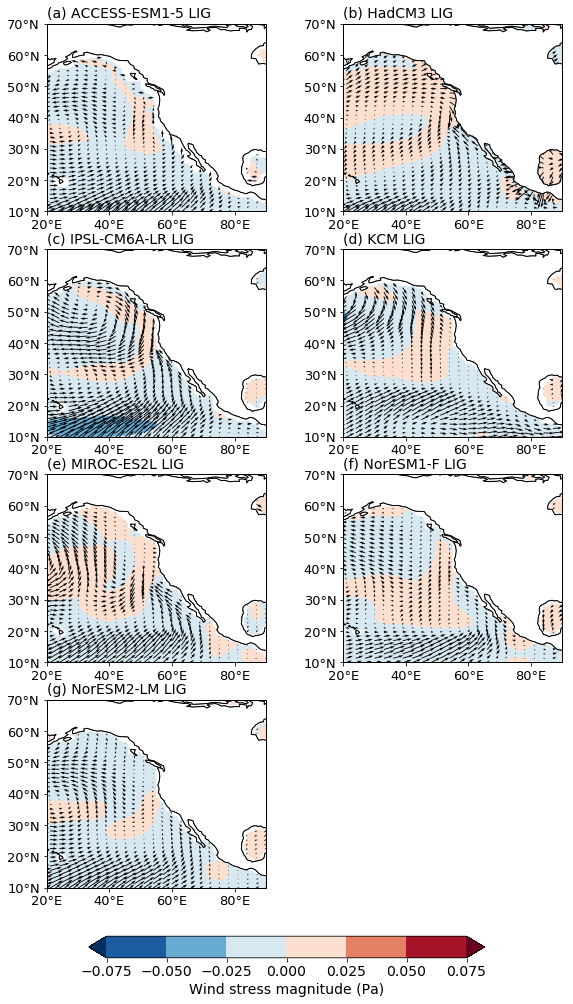

In [8]:
### Northeast Pacific EBUS

x_coords = PI_models_u_ann[0].coord('longitude').points[::3]
y_coords = PI_models_v_ann[0].coord('latitude').points[::3]

fig = plt.figure(figsize=(10, 15))
axes = []
for i in range(1, 7+1):
    ax = fig.add_subplot(4, 2, i, projection=ccrs.PlateCarree(central_longitude=180))
    axes.append(ax)
    
titles = [ '(a) ACCESS-ESM1-5', '(b) HadCM3', '(c) IPSL-CM6A-LR', '(d) KCM', '(e) MIROC-ES2L', '(f) NorESM1-F', '(g) NorESM2-LM']

for i, (ax, t) in enumerate(zip(axes, titles)):
    
    ax.add_feature(cartopy.feature.LAND, facecolor='white')
    ax.add_feature(cartopy.feature.COASTLINE, edgecolor='black', linewidth=1)
    ax.yaxis.set_major_formatter(LATITUDE_FORMATTER)
    
    ax.set_yticks(np.arange(0, 70+10, 10))
    ax.tick_params(axis='y', labelsize=13)
    ax.set_xticks([-80, -60, -40, -20, 0, 20, 40, 60, 80], crs=ccrs.PlateCarree(central_longitude=180))
    ax.set_xticklabels(['80°W', '60°W', '40°W', '20°W', '180°', '20°E', '40°E', '60°E', '80°E'])
    ax.tick_params(axis='x', labelsize=13)
    ax.set_ylim(10, 70)
    ax.set_xlim(20, 90)
    
    ax.set_title(t + ' LIG', fontsize=14, loc='left')
    levels = np.linspace(-0.075, 0.075, 7)
    # magnitudes
    cf = iplt.contourf(diff_magnitudes[i], levels=levels, axes=ax, cmap='RdBu_r', extend='both')
    # vectores
    ax.quiver(x_coords, y_coords, diff_u[i].data[::3, ::3], diff_v[i].data[::3, ::3],
              transform=ccrs.PlateCarree(), scale = .3, width=0.004, color='k')
    ax.coastlines(linewidth=0.5)
    #ax.gridlines(draw_labels=False, linewidth=0.3, linestyle='--', color='gray')
    #ax.set_global()
# Colourbar
cbar_ax = fig.add_axes([0.2, 0.035, 0.55, 0.02])# [left, bottom, width, height]
cbar = fig.colorbar(cf, cax=cbar_ax, orientation='horizontal')
cbar.set_label('Wind stress magnitude (Pa)', size=14)
cbar.ax.tick_params(labelsize=14)
     
plt.subplots_adjust(left=0.1,bottom=0.1,right=0.9,top=0.9,wspace=0.06,hspace=0.2)   
#plt.savefig('/nfs/see-fs-01_users/mlzp121/Test_HadCM3_simulations/wind_stress_vectors_dif_NEPacific.png', bbox_inches = 'tight', dpi=300, format='png')
plt.show()

### MMM

In [9]:
x_coords = PI_models_u_ann[0].coord('longitude').points[::7]
y_coords = PI_models_v_ann[0].coord('latitude').points[::7]

In [10]:
### MMMM
mmm_dif_u = [cube.copy() for cube in diff_u]
mmm_dif_v = [cube.copy() for cube in diff_v]
mmm_dif_mag = [cube.copy() for cube in diff_magnitudes]

MMM_u_dif = sum([mmm_dif_u[i].data for i in range(np.size(mmm_dif_u))])/7
MMM_v_dif = sum([mmm_dif_v[i].data for i in range(np.size(mmm_dif_v))])/7
MMM_mag_dif = sum([mmm_dif_mag[i].data for i in range(np.size(mmm_dif_mag))])/7

MMM_u_dif_cube = diff_u[0].copy(data = MMM_u_dif)
MMM_v_dif_cube = diff_v[0].copy(data = MMM_v_dif)
MMM_mag_dif_cube = diff_magnitudes[0].copy(data = MMM_mag_dif)

In [11]:
# Spread de la magnitud
sig_dif_mag = []

for n in range(np.size(PI_models_u_ann)):
    diff_mag_data = diff_magnitudes[n].data

    threshold = 0.0001

    # Magnitud
    signed_diff_mag = np.where(diff_mag_data >= threshold, 1, np.where(diff_mag_data <= -threshold, -1, 0))
    sig_dif_mag.append(signed_diff_mag)

# Sum
sum_sig_dif_mag = np.sum(sig_dif_mag, axis=0)

# At least 5 models agreeing in sign
consensus_mag_values    = np.where(np.abs(sum_sig_dif_mag) >= 5, sum_sig_dif_mag, np.nan)
consensus_mag_cube      = MMM_mag_dif_cube.copy(data=consensus_mag_values)
non_consensus_mag_mask  = np.abs(sum_sig_dif_mag) < 5
non_consensus_mag_cube  = MMM_mag_dif_cube.copy(data=non_consensus_mag_mask.astype(float))

/apps/developers/compilers/canopy3/2.1.3/1/bit-64/Canopy/edm/envs/User/lib/python3.5/site-packages/ipykernel/__main__.py:10: RuntimeWarning: invalid value encountered in greater_equal
/apps/developers/compilers/canopy3/2.1.3/1/bit-64/Canopy/edm/envs/User/lib/python3.5/site-packages/ipykernel/__main__.py:10: RuntimeWarning: invalid value encountered in less_equal


Self-intersection at or near point -180 -65.390625


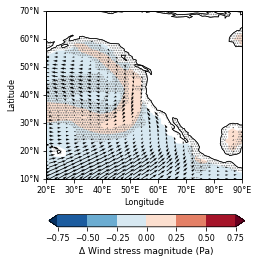

In [12]:
### Plot Northeast Pacific MMM
x_coords_np = PI_models_u_ann[0].coord('longitude').points[::3]
y_coords_np = PI_models_v_ann[0].coord('latitude').points[::3]

fig = plt.figure(figsize=(3.4, 3.4))
proj = ccrs.PlateCarree(central_longitude=180)
ax = fig.add_subplot(1, 1, 1, projection=proj)

ax.add_feature(cartopy.feature.LAND, facecolor='white')
ax.add_feature(cartopy.feature.COASTLINE, edgecolor='black', linewidth=0.7)
ax.yaxis.set_major_formatter(LATITUDE_FORMATTER)
    
ax.set_yticks(np.arange(0, 70+10, 10))
ax.tick_params(axis='y', labelsize=8)
ax.set_xticks([-80, -60, -40, -20, 0, 20, 30, 40, 50, 60, 70, 80, 90], crs=ccrs.PlateCarree(central_longitude=180))
ax.set_xticklabels(['80°W', '60°W', '40°W', '20°W', '180°', '20°E', '30°E','40°E', '50°E', '60°E', '70°E','80°E','90°E'])
ax.tick_params(axis='x', labelsize=8)
ax.set_ylim(10, 70)
ax.set_xlim(20, 90)
    
levels = np.linspace(-0.75, 0.75, 7)
# magnitude
cf = iplt.contourf(MMM_mag_dif_cube, levels=levels, axes=ax, cmap='RdBu_r', extend='both')
# Hatching Non consensus
mpl.rcParams['hatch.color'] = 'gray'
iplt.contourf(non_consensus_mag_cube, levels=[0.5, 1.5], colors='none', 
              hatches=['.....'], extend='neither', axes=ax)
# Wind vectors
ax.quiver(x_coords_np, y_coords_np, MMM_u_dif_cube.data[::3, ::3], MMM_v_dif_cube.data[::3, ::3],
            transform=ccrs.PlateCarree(), scale=.3, width=0.004, color='k')
ax.coastlines(linewidth=0.5)
#ax.gridlines(draw_labels=False, linewidth=1, linestyle='--', color='grey')
#ax.set_global()
# Colourbar
cbar_ax = fig.add_axes([0.11, -0.04, 0.8, 0.05])# [left, bottom, width, height]
cbar = fig.colorbar(cf, cax=cbar_ax, orientation='horizontal')
cbar.set_label('Δ Wind stress magnitude (Pa)', size=9)
cbar.ax.tick_params(labelsize=8)
     
plt.subplots_adjust(left=0.1,bottom=0.1,right=0.9,top=0.9,wspace=0.1,hspace=0.2)
# Shared axis labels
fig.text(-0.06, 0.5, 'Latitude', va='center', rotation='vertical', fontsize=8)
fig.text(0.5, 0.05, 'Longitude', ha='center', fontsize=8)
#plt.savefig('/nfs/see-fs-01_users/mlzp121/Test_HadCM3_simulations/wind_stress_diff_mmm_NE_Pacific.png', bbox_inches='tight', dpi=300, format='png')
plt.show()